In [1]:
%%bash
[[ ! -e /content/sample_data ]] && exit  ## run this cell only in colab
 
pip install optax -qqq
pip install networkx==2.5 -qqq
pip install netgraph
git clone https://github.com/ramithuh/differentiable-trees --quiet

In [2]:
%load_ext autoreload
%autoreload 2

import os
import sys

if(os.path.exists('/content/sample_data')):
  sys.path.append('differentiable-trees/')

import jax.numpy as jnp
import jax.nn as nn
import jax
import optax
import functools

import pydot
import numpy as np
from helpers import *

from matplotlib import rc
rc('animation', html='jshtml')

In [3]:
key = jax.random.PRNGKey(42)

## Sequences

In [4]:
# sequences (fixed)
n_leaves    = 4
n_ancestors = n_leaves - 1

seq_length = 10

n_all = n_leaves + n_ancestors

metadata = {
            'n_all' : n_all,
            'n_leaves' : n_leaves, 
            'n_ancestors' : n_ancestors 
            }

blank = jnp.array([0,0,0,0])

In [5]:
# similarity matrix (fixed)
sm = jnp.array([[0,1],
               [1,0]])

In [6]:
seqs = jax.random.randint(key, shape = (n_all, seq_length), minval = 0, maxval = 2)

#### Custom Seq

In [7]:
seqs = jnp.array([
 [1, 0, 0, 0, 0, 0, 1, 0, 0, 0],
 [1, 0, 0, 0, 0, 0, 0, 0, 0, 1],
 [0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
 [0, 0, 1, 1, 0, 0, 0, 0, 0, 0],
 [0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
 [0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
 [0, 0, 0, 0, 0, 0, 0, 0, 0, 0]]).astype(jnp.float32)

In [8]:
seqs.dtype

dtype('float32')

In [9]:
base_tree = jnp.zeros((n_all, n_all))

In [10]:
seqs

DeviceArray([[1., 0., 0., 0., 0., 0., 1., 0., 0., 0.],
             [1., 0., 0., 0., 0., 0., 0., 0., 0., 1.],
             [0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
             [0., 0., 1., 1., 0., 0., 0., 0., 0., 0.],
             [0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
             [0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
             [0., 0., 0., 0., 0., 0., 0., 0., 0., 0.]], dtype=float32)

## Tree Topology (also parameterized)

### initialize parameters

In [11]:
optimizer = optax.adam(1)

params = {'t': jax.random.normal(key, (n_all - 1,n_ancestors))}


for i in range(0, n_ancestors):
    params[chr(97+i + n_leaves)] = jax.random.normal(key, (seq_length,))
    

opt_state = optimizer.init(params)

In [12]:
params.keys()

dict_keys(['t', 'e', 'f', 'g'])

In [13]:
# t_q = jnp.argmax(t_softmax,axis = 1).T

In [14]:
base_tree.shape

(7, 7)

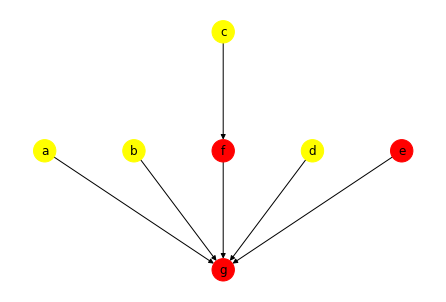

In [15]:
show_graph_with_labels(discretize_tree_topology(update_tree(params, base_tree), n_all),n_leaves)

### Function to compute total distance

In [16]:
def compute_cost(sequences, tree, verbose = False, average = True):
    if(verbose==True):
        show_graph_with_labels(discretize_tree_topology(tree, n_all),n_leaves)
        
    selection = jnp.matmul(tree,sequences)
    # print(selection)
    
#     #method 1: (downside needs integers as we are indexing)
#     selection = selection.astype(int)
#     ans = sm[selection,sequences].sum()
    
    #method 2:
    if(average):
        ans = abs(selection - sequences).sum() ## works currently as sm is the basic config. need to think about extending
    else:
        ans = jnp.sum(abs(selection - sequences), axis = 1)
    
    return ans

In [17]:
update_tree(params, base_tree)

DeviceArray([[0.        , 0.        , 0.        , 0.        , 0.30321804,
              0.16727467, 0.5295073 ],
             [0.        , 0.        , 0.        , 0.        , 0.3965519 ,
              0.12775946, 0.4756886 ],
             [0.        , 0.        , 0.        , 0.        , 0.12712821,
              0.8479232 , 0.02494855],
             [0.        , 0.        , 0.        , 0.        , 0.31710118,
              0.2897718 , 0.39312702],
             [0.        , 0.        , 0.        , 0.        , 0.20008957,
              0.17309996, 0.62681043],
             [0.        , 0.        , 0.        , 0.        , 0.14293277,
              0.3836567 , 0.47341058],
             [0.        , 0.        , 0.        , 0.        , 0.        ,
              0.        , 1.        ]], dtype=float32)

DeviceArray(6., dtype=float32)

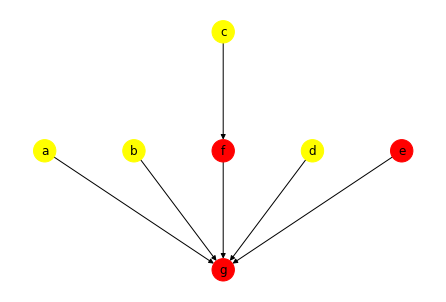

In [18]:
compute_cost(seqs,update_tree(params, base_tree),1)

In [19]:
seqs

DeviceArray([[1., 0., 0., 0., 0., 0., 1., 0., 0., 0.],
             [1., 0., 0., 0., 0., 0., 0., 0., 0., 1.],
             [0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
             [0., 0., 1., 1., 0., 0., 0., 0., 0., 0.],
             [0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
             [0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
             [0., 0., 0., 0., 0., 0., 0., 0., 0., 0.]], dtype=float32)

In [20]:
print(i)

2


In [21]:
# i = 0
# key = chr(97+i + n_leaves)

# seq      = nn.sigmoid(1*params[key])
# hard_seq = (seq > 0.5).astype(int)

# print(hard_seq)

# hard_seq = hard_seq.at[0].set(2)


# seqs = seqs.at[- n_leaves + i].set(hard_seq)

In [22]:
# hard_seq

In [23]:
# - n_leaves + i

In [24]:
seqs

DeviceArray([[1., 0., 0., 0., 0., 0., 1., 0., 0., 0.],
             [1., 0., 0., 0., 0., 0., 0., 0., 0., 1.],
             [0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
             [0., 0., 1., 1., 0., 0., 0., 0., 0., 0.],
             [0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
             [0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
             [0., 0., 0., 0., 0., 0., 0., 0., 0., 0.]], dtype=float32)

In [25]:
combine_to_seq(params, seqs, n_leaves, n_all)

DeviceArray([[1.        , 0.        , 0.        , 0.        , 0.        ,
              0.        , 1.        , 0.        , 0.        , 0.        ],
             [1.        , 0.        , 0.        , 0.        , 0.        ,
              0.        , 0.        , 0.        , 0.        , 1.        ],
             [0.        , 0.        , 0.        , 0.        , 0.        ,
              0.        , 0.        , 0.        , 0.        , 0.        ],
             [0.        , 0.        , 1.        , 1.        , 0.        ,
              0.        , 0.        , 0.        , 0.        , 0.        ],
             [0.59121835, 0.38682562, 0.29627627, 0.7699605 , 0.7316608 ,
              0.29508665, 0.40167284, 0.33916688, 0.5834357 , 0.5982611 ],
             [0.59121835, 0.38682562, 0.29627627, 0.7699605 , 0.7316608 ,
              0.29508665, 0.40167284, 0.33916688, 0.5834357 , 0.5982611 ],
             [0.59121835, 0.38682562, 0.29627627, 0.7699605 , 0.7316608 ,
              0.29508665, 0.4016

In [26]:
params

{'t': DeviceArray([[-0.63462436, -1.2294393 , -0.07712954],
              [-0.22857422, -1.3612318 , -0.04661765],
              [-0.14380704,  1.7537868 , -1.7721876 ],
              [ 0.18559739,  0.09547025,  0.40050933],
              [ 0.9773695 ,  0.83247375,  2.1192486 ],
              [-0.67893344,  0.3084403 ,  0.51865524]], dtype=float32),
 'e': DeviceArray([ 0.36900434, -0.46067542, -0.8650934 ,  1.2080883 ,
               1.003065  , -0.8708058 , -0.3984997 , -0.6670092 ,
               0.33689356,  0.39822492], dtype=float32),
 'f': DeviceArray([ 0.36900434, -0.46067542, -0.8650934 ,  1.2080883 ,
               1.003065  , -0.8708058 , -0.3984997 , -0.6670092 ,
               0.33689356,  0.39822492], dtype=float32),
 'g': DeviceArray([ 0.36900434, -0.46067542, -0.8650934 ,  1.2080883 ,
               1.003065  , -0.8708058 , -0.3984997 , -0.6670092 ,
               0.33689356,  0.39822492], dtype=float32)}

In [27]:
n_all

7

In [28]:
# tree_force_loss = 0 

# t_new = discretize_tree_topology(update_tree(params, base_tree), n_leaves + n_ancestors)

# for k in range(n_all - 1, n_all - 1 - n_ancestors, -1):
#     tree_force_loss += (abs(t_new[:-1,k].sum()-2))**2

# print(tree_force_loss)

In [29]:
def regularize_graph(t_, s, verbose = False):
    
    tree_force_loss = jnp.sum(jnp.power(s*jnp.abs(jnp.sum(t_[:-1, n_all - n_ancestors: n_all], axis = 0) - 2),2))
    
    #tree_force_loss = (s*abs(t_[:-1,-2].sum()-2))**2 + (s*abs(t_[:-1,-1].sum()-2))**2
    
    loop_loss = jnp.multiply(jnp.identity(n_all-1), t_[:-1,:-1]).sum()*100  ## penalize self connections
    
    
    if(verbose):
        print("bifurcating tree_forcing_loss = ", tree_force_loss)
        print("self loop_loss = ", loop_loss)
    
    return tree_force_loss + loop_loss

In [30]:
def compute_loss(params, seqs, base_tree, verbose = False):
    seqs_ = combine_to_seq(params, seqs, n_leaves, n_all)
    t_    = update_tree(params, base_tree)

    loss  = compute_cost(seqs_,t_) + enforce_graph(t_,10,metadata, verbose)
    
    return loss

In [31]:
compute_loss(params, seqs, base_tree)

DeviceArray(132.81854, dtype=float32)

In [32]:
trees = []

for _ in range(1500):
    grads = jax.grad(compute_loss)(params, seqs, base_tree)
    
    
    t_= update_tree(params, base_tree)
    t__ = discretize_tree_topology(t_,n_all)
    t__ = t__.at[-1,-1].set(0)
    
    trees.append(t__)
    
    if(_%100==0):
        # temp  = combine_to_seq(params, seqs)
        
        print("{:.5f}".format(compute_loss(params, seqs, base_tree)),end = " seq = {}\n")
        #print(t_[:,-2],",",t_[:,-1],end="}\n")
    updates, opt_state = optimizer.update(grads, opt_state)
    params = optax.apply_updates(params, updates)


132.81854 seq = {}
6.02671 seq = {}
6.01967 seq = {}
6.01648 seq = {}
6.01422 seq = {}
6.01240 seq = {}
6.01089 seq = {}
6.00963 seq = {}
6.00855 seq = {}
6.00763 seq = {}
6.00684 seq = {}
6.00616 seq = {}
6.00557 seq = {}
6.00505 seq = {}
6.00459 seq = {}


In [33]:
adjacency_matrix2 = jnp.array(trees)

<__array_function__ internals>:180: VisibleDeprecationWarning: Creating an ndarray from ragged nested sequences (which is a list-or-tuple of lists-or-tuples-or ndarrays with different lengths or shapes) is deprecated. If you meant to do this, you must specify 'dtype=object' when creating the ndarray.
/n/home12/ramith/.conda/envs/jax_python38/lib/python3.8/site-packages/netgraph/_utils.py:395: RuntimeWarning: invalid value encountered in divide
  unit_vector = vector / np.linalg.norm(vector)


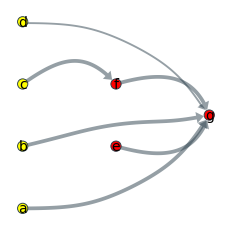

In [34]:
anim = animate_tree(adjacency_matrix2, n_leaves, n_ancestors, total_frames = 500 )

In [35]:
#anim.save(f"nodes_{n_all}.mp4")

In [36]:
t_new = discretize_tree_topology(update_tree(params, base_tree), n_leaves + n_ancestors)

In [37]:
discretized = jnp.round(combine_to_seq(params, seqs, n_leaves, n_all))

In [38]:
compute_loss(params, seqs, base_tree, 1)

bifurcating tree_forcing_loss =  5.3184005e-05
self loop_loss =  0.0008595417
bidirectional loss =  1.0


DeviceArray(6.004195, dtype=float32)

In [39]:
t_new

DeviceArray([[0., 0., 0., 0., 1., 0., 0.],
             [0., 0., 0., 0., 1., 0., 0.],
             [0., 0., 0., 0., 0., 1., 0.],
             [0., 0., 0., 0., 0., 1., 0.],
             [0., 0., 0., 0., 0., 0., 1.],
             [0., 0., 0., 0., 0., 0., 1.],
             [0., 0., 0., 0., 0., 0., 1.]], dtype=float32)

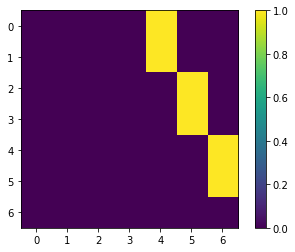

In [40]:
plt.imshow(adjacency_matrix2[300])
plt.colorbar()

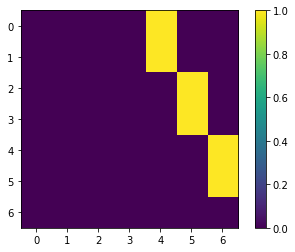

In [41]:
plt.imshow(adjacency_matrix2[-1])
plt.colorbar()


## Retrieving the new sequences array

In [42]:
t_new = discretize_tree_topology(update_tree(params, base_tree), n_leaves + n_ancestors)

In [43]:
combine_to_seq(params, seqs, n_leaves, n_all)

DeviceArray([[1.00000000e+00, 0.00000000e+00, 0.00000000e+00,
              0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
              1.00000000e+00, 0.00000000e+00, 0.00000000e+00,
              0.00000000e+00],
             [1.00000000e+00, 0.00000000e+00, 0.00000000e+00,
              0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
              0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
              1.00000000e+00],
             [0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
              0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
              0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
              0.00000000e+00],
             [0.00000000e+00, 0.00000000e+00, 1.00000000e+00,
              1.00000000e+00, 0.00000000e+00, 0.00000000e+00,
              0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
              0.00000000e+00],
             [9.99983072e-01, 3.09102688e-06, 9.69827852e-06,
              1.11097361e-05, 6.05331570e-06, 2.47063099e-06,
        

In [44]:
discretized = jnp.round(combine_to_seq(params, seqs, n_leaves, n_all))

In [45]:
discretized

DeviceArray([[1., 0., 0., 0., 0., 0., 1., 0., 0., 0.],
             [1., 0., 0., 0., 0., 0., 0., 0., 0., 1.],
             [0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
             [0., 0., 1., 1., 0., 0., 0., 0., 0., 0.],
             [1., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
             [0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
             [0., 0., 0., 0., 0., 0., 0., 0., 0., 0.]], dtype=float32)

In [46]:
seqs

DeviceArray([[1., 0., 0., 0., 0., 0., 1., 0., 0., 0.],
             [1., 0., 0., 0., 0., 0., 0., 0., 0., 1.],
             [0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
             [0., 0., 1., 1., 0., 0., 0., 0., 0., 0.],
             [0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
             [0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
             [0., 0., 0., 0., 0., 0., 0., 0., 0., 0.]], dtype=float32)

In [47]:
params

{'e': DeviceArray([ 10.985193, -12.687004, -11.543552, -11.407678, -12.014898,
              -12.911035, -11.695423, -12.164862, -12.39838 , -11.44478 ],            dtype=float32),
 'f': DeviceArray([-11.259275 , -12.048363 , -11.404148 , -10.5468445,
              -12.206297 , -12.231602 , -12.038743 , -12.521122 ,
              -11.88493  , -12.216202 ], dtype=float32),
 'g': DeviceArray([ -4.7862277, -12.048239 , -11.405313 , -10.546484 ,
              -12.0146675, -12.230316 , -11.696994 , -12.163507 ,
              -11.884669 , -11.444263 ], dtype=float32),
 't': DeviceArray([[ 5.324903 , -2.0246577, -3.981581 ],
              [ 4.8241854, -2.948513 , -2.8563902],
              [-2.9600463,  5.351629 , -7.715829 ],
              [-1.5185843,  5.221886 , -3.3469174],
              [-3.7929738,  1.1115369,  7.894745 ],
              [-4.1348596, -8.72569  ,  6.6567626]], dtype=float32)}

### New cost

In [48]:
t_new

DeviceArray([[0., 0., 0., 0., 1., 0., 0.],
             [0., 0., 0., 0., 1., 0., 0.],
             [0., 0., 0., 0., 0., 1., 0.],
             [0., 0., 0., 0., 0., 1., 0.],
             [0., 0., 0., 0., 0., 0., 1.],
             [0., 0., 0., 0., 0., 0., 1.],
             [0., 0., 0., 0., 0., 0., 1.]], dtype=float32)

DeviceArray(5., dtype=float32)

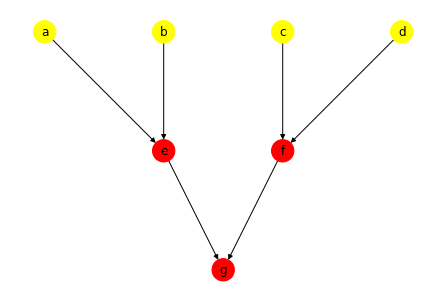

In [49]:
compute_cost(discretized, t_new, 1)

In [50]:
t_new

DeviceArray([[0., 0., 0., 0., 1., 0., 0.],
             [0., 0., 0., 0., 1., 0., 0.],
             [0., 0., 0., 0., 0., 1., 0.],
             [0., 0., 0., 0., 0., 1., 0.],
             [0., 0., 0., 0., 0., 0., 1.],
             [0., 0., 0., 0., 0., 0., 1.],
             [0., 0., 0., 0., 0., 0., 1.]], dtype=float32)

### Old cost

In [51]:
compute_cost(seqs, base_tree) ##when d & e were all zeros

DeviceArray(6., dtype=float32)

### test arbitrary sequence for d & e

In [52]:
test = jnp.array([[0, 0., 0., 0.],
                 [1., 0., 0., 1.],
                 [0., 1., 1., 0.],
                 [0., 0., 0., 0.],
                 [0., 0., 0., 0.]])

In [53]:
# compute_cost(test, t_new)